# Atividade 3 — Regressão Logística (Softmax): Classificação de Tumores de Mama

Nesta atividade treinamos uma **regressão logística** em PyTorch para classificar tumores de mama como **malignos (0)** ou **benignos (1)**.

O dataset *Breast Cancer Wisconsin* vem no scikit-learn e contém **569 amostras** com **30 variáveis** numéricas extraídas de imagens de biópsia.

## Importação das bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import torch
from torch import nn, optim

torch.manual_seed(42)
np.random.seed(42)

## 1. Análise dos dados

### 1.1 Carregamento

In [5]:
dados = load_breast_cancer(as_frame=True)
X, y = dados.data, dados.target   # 569 amostras, 30 variáveis; 0 = maligno, 1 = benigno

print('Shape de X:', X.shape)
print('Shape de y:', y.shape)
print('\nClasses:', dados.target_names.tolist(), '→ 0 = maligno, 1 = benigno')

Shape de X: (569, 30)
Shape de y: (569,)

Classes: ['malignant', 'benign'] → 0 = maligno, 1 = benigno


### 1.2 Quantas amostras de cada classe?

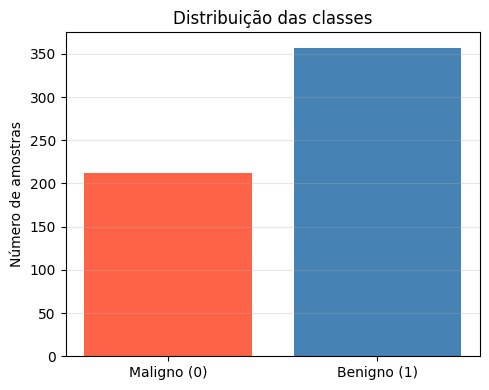

In [4]:
contagem = y.value_counts().sort_index()  # garante ordem: 0 (maligno), 1 (benigno)
contagem.index = ['Maligno (0)', 'Benigno (1)']

plt.figure(figsize=(5, 4))
plt.bar(['Maligno (0)', 'Benigno (1)'], contagem.values, color=['tomato', 'steelblue'])
plt.ylabel('Número de amostras')
plt.title('Distribuição das classes')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.3 O que as variáveis medem?

O dataset tem 30 variáveis numéricas extraídas de imagens de biópsias. Para cada um dos 10 atributos abaixo, foram calculadas **média, erro padrão e pior valor** (daí 10 × 3 = 30 colunas):

| Atributo | Significado |
|---|---|
| `radius` | Raio médio do núcleo celular |
| `texture` | Variação nos tons de cinza |
| `perimeter` | Perímetro do núcleo |
| `area` | Área do núcleo |
| `smoothness` | Suavidade do contorno (variação local do raio) |
| `compactness` | Compacidade (perímetro² / área − 1) |
| `concavity` | Severidade das concavidades do contorno |
| `concave points` | Número de pontos côncavos |
| `symmetry` | Simetria do núcleo |
| `fractal dimension` | Dimensão fractal do contorno |

Tumores malignos tendem a ter núcleos **maiores, mais irregulares e assimétricos**.

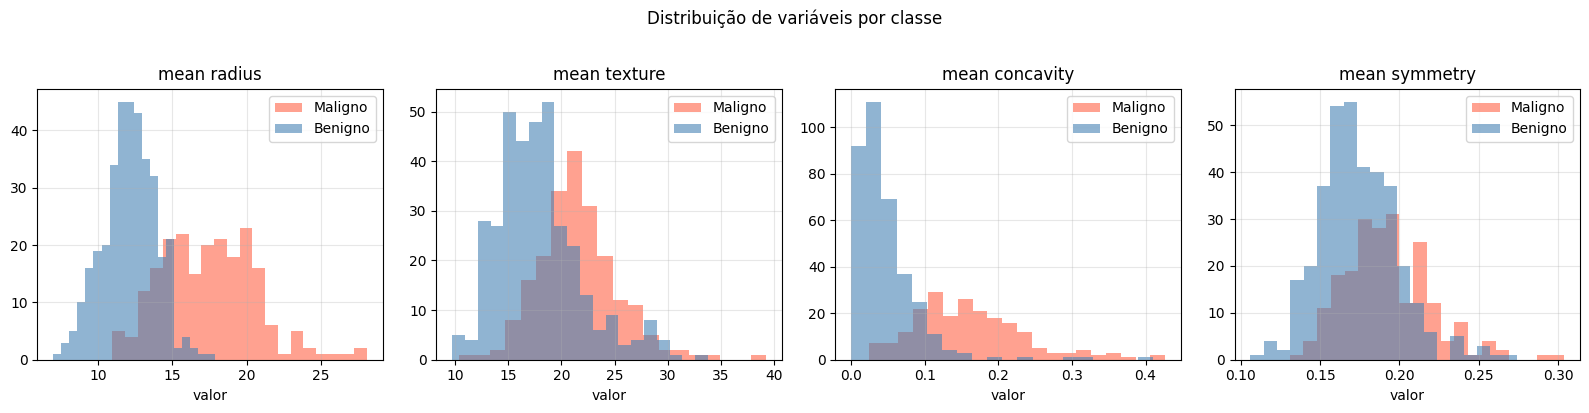

In [6]:
# Comparação de 4 variáveis entre maligno e benigno
vars_interesse = ['mean radius', 'mean texture', 'mean concavity', 'mean symmetry']
df = X[vars_interesse].copy()
df['classe'] = y.map({0: 'Maligno', 1: 'Benigno'})

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, var in zip(axes, vars_interesse):
    for classe, cor in [('Maligno', 'tomato'), ('Benigno', 'steelblue')]:
        vals = df[df['classe'] == classe][var]
        ax.hist(vals, bins=20, alpha=0.6, label=classe, color=cor)
    ax.set_title(var)
    ax.set_xlabel('valor')
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.suptitle('Distribuição de variáveis por classe', y=1.02)
plt.tight_layout()
plt.show()

## 2. Divisão treino/teste e padronização

### 2.1 Split estratificado (80/20)

In [7]:
X_np = X.to_numpy().astype(np.float32)
y_np = y.to_numpy().astype(np.int64)  # CrossEntropyLoss espera int64

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_np, y_np, test_size=0.20, random_state=42, stratify=y_np)

print(f'Treino: {X_train_raw.shape[0]} amostras')
print(f'Teste:  {X_test_raw.shape[0]} amostras')
print(f'\nProporção maligno no treino: {(y_train_raw == 0).mean()*100:.1f}%')
print(f'Proporção maligno no teste:  {(y_test_raw == 0).mean()*100:.1f}%')

Treino: 455 amostras
Teste:  114 amostras

Proporção maligno no treino: 37.4%
Proporção maligno no teste:  36.8%


### 2.2 Padronização com StandardScaler (ajustado **só no treino**)


In [8]:
scaler = StandardScaler().fit(X_train_raw)  # fit APENAS no treino

x_train = torch.from_numpy(scaler.transform(X_train_raw)).float()
y_train = torch.from_numpy(y_train_raw).long()

x_test = torch.from_numpy(scaler.transform(X_test_raw)).float()
y_test = torch.from_numpy(y_test_raw).long()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_test: ', x_test.shape,  ' y_test: ', y_test.shape)

x_train: torch.Size([455, 30])  y_train: torch.Size([455])
x_test:  torch.Size([114, 30])  y_test:  torch.Size([114])


## 3. Modelo e treinamento

### 3.1 Modelo

`nn.Linear(30, 2)`: 30 entradas (uma por variável) e **2 saídas** (um logit por classe). A `CrossEntropyLoss` aplica a softmax internamente — não precisamos de uma camada softmax explícita.

In [9]:
model = nn.Linear(30, 2)
print(model)
print('Parâmetros totais:', sum(p.numel() for p in model.parameters()))

Linear(in_features=30, out_features=2, bias=True)
Parâmetros totais: 62


### 3.2 Função de custo e otimizador

In [10]:
lr = 0.1
n_epochs = 200

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

### 3.3 Laço de treinamento

Em cada época: forward → custo → `zero_grad()` → `backward()` → `step()`. Guardamos o custo de treino e de teste para plotar as curvas.

In [11]:
train_losses = []
test_losses  = []

for epoch in range(n_epochs):
    # Treino
    model.train()
    logits_train = model(x_train)
    loss_train = criterion(logits_train, y_train)
    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()
    train_losses.append(loss_train.item())

    # Teste (sem gradiente)
    model.eval()
    with torch.no_grad():
        logits_test = model(x_test)
        loss_test = criterion(logits_test, y_test)
    test_losses.append(loss_test.item())

    if (epoch + 1) % 40 == 0:
        print(f'Época [{epoch+1}/{n_epochs}]  '
              f'custo treino: {loss_train.item():.4f}  '
              f'custo teste: {loss_test.item():.4f}')

Época [40/200]  custo treino: 0.1054  custo teste: 0.1427
Época [80/200]  custo treino: 0.0849  custo teste: 0.1199
Época [120/200]  custo treino: 0.0762  custo teste: 0.1098
Época [160/200]  custo treino: 0.0711  custo teste: 0.1039
Época [200/200]  custo treino: 0.0677  custo teste: 0.0999


### 3.4 Curvas de custo

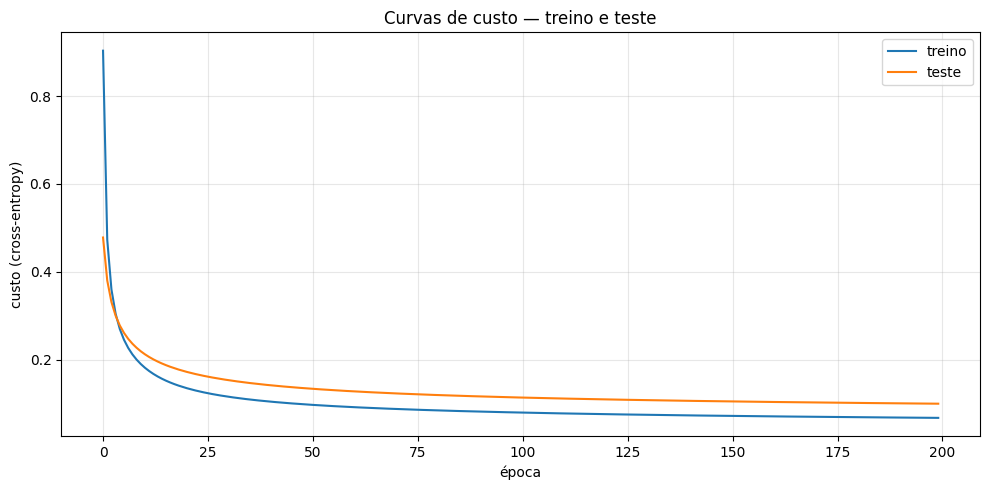

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='treino')
plt.plot(test_losses,  label='teste')
plt.xlabel('época')
plt.ylabel('custo (cross-entropy)')
plt.title('Curvas de custo — treino e teste')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Avaliação: acurácia vs baseline

O **baseline** é o classificador mais simples possível: sempre prevê a classe mais frequente (benigno, que é maioria). Qualquer modelo útil precisa superar isso.

In [13]:
model.eval()
with torch.no_grad():
    logits = model(x_test)
    y_pred = logits.argmax(dim=1)

acuracia_modelo = (y_pred == y_test).float().mean().item()

# Baseline: sempre prevê a classe mais frequente no treino
classe_mais_frequente = int(torch.mode(y_train).values.item())
y_baseline = torch.full_like(y_test, classe_mais_frequente)
acuracia_baseline = (y_baseline == y_test).float().mean().item()

print(f'Classe mais frequente no treino: {classe_mais_frequente} ({"benigno" if classe_mais_frequente == 1 else "maligno"})')
print(f'\nAcurácia do baseline: {acuracia_baseline*100:.1f}%')
print(f'Acurácia do modelo:   {acuracia_modelo*100:.1f}%')
print(f'Melhoria:             +{(acuracia_modelo - acuracia_baseline)*100:.1f} p.p.')

Classe mais frequente no treino: 1 (benigno)

Acurácia do baseline: 63.2%
Acurácia do modelo:   97.4%
Melhoria:             +34.2 p.p.


## 5. Matriz de confusão e recall da classe maligno

### 5.1 Matriz de confusão

Linhas = classe **prevista**, colunas = classe **real**.

- **Verdadeiro Positivo (VP)**: maligno previsto como maligno ✓
- **Falso Negativo (FN)**: maligno previsto como benigno ✗ ← **erro mais grave**
- **Falso Positivo (FP)**: benigno previsto como maligno ✗
- **Verdadeiro Negativo (VN)**: benigno previsto como benigno ✓

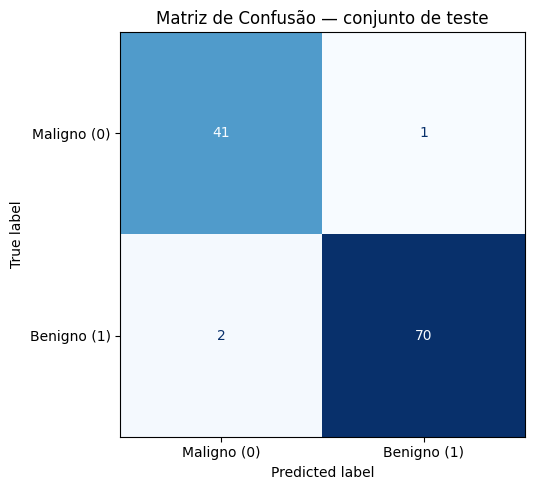


Matriz de confusão:
               Previsto: Maligno  Previsto: Benigno
Real: Maligno                 41                  1
Real: Benigno                  2                 70


In [14]:
y_pred_np = y_pred.numpy()
y_test_np = y_test.numpy()

cm = confusion_matrix(y_test_np, y_pred_np)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Maligno (0)', 'Benigno (1)'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Matriz de Confusão — conjunto de teste')
plt.tight_layout()
plt.show()

print('\nMatriz de confusão:')
print(pd.DataFrame(cm,
                   index=['Real: Maligno', 'Real: Benigno'],
                   columns=['Previsto: Maligno', 'Previsto: Benigno']))

### 5.2 Recall da classe maligno

$$\text{Recall (maligno)} = \frac{\text{Malignos detectados corretamente}}{\text{Total de malignos reais}} = \frac{VP}{VP + FN}$$

Significa: de cada 100 tumores malignos reais, quantos o modelo conseguiu identificar como malignos?

In [15]:
# Malignos são a classe 0
VP = cm[0, 0]  # maligno previsto como maligno
FN = cm[0, 1]  # maligno previsto como benigno
FP = cm[1, 0]  # benigno previsto como maligno
VN = cm[1, 1]  # benigno previsto como benigno

recall_maligno  = VP / (VP + FN)
precisao_maligno = VP / (VP + FP)

print(f'Verdadeiros Positivos (VP): {VP}  — malignos detectados corretamente')
print(f'Falsos Negativos (FN):      {FN}  — malignos classificados como benigno ← erro grave')
print(f'Falsos Positivos (FP):      {FP}  — benignos classificados como maligno')
print(f'Verdadeiros Negativos (VN): {VN}  — benignos detectados corretamente')
print(f'\nRecall (maligno):   {recall_maligno*100:.1f}%  '
      f'→ de cada 100 tumores malignos, o modelo detecta {recall_maligno*100:.0f}')
print(f'Precisão (maligno): {precisao_maligno*100:.1f}%')

Verdadeiros Positivos (VP): 41  — malignos detectados corretamente
Falsos Negativos (FN):      1  — malignos classificados como benigno ← erro grave
Falsos Positivos (FP):      2  — benignos classificados como maligno
Verdadeiros Negativos (VN): 70  — benignos detectados corretamente

Recall (maligno):   97.6%  → de cada 100 tumores malignos, o modelo detecta 98
Precisão (maligno): 95.3%


## 6. Discussão: qual erro é mais grave?

### Falso Negativo vs Falso Positivo

| Tipo de erro | O que acontece | Consequência |
|---|---|---|
| **Falso Negativo (FN)** | Tumor maligno classificado como benigno | Paciente não recebe tratamento → risco de vida |
| **Falso Positivo (FP)** | Tumor benigno classificado como maligno | Exames adicionais desnecessários, ansiedade |

**O falso negativo é muito mais grave**: um câncer não detectado pode progredir e matar o paciente, enquanto um falso positivo leva apenas a exames extras.

### O que mudar para reduzir o erro mais grave?

Para maximizar o recall da classe maligno (reduzir FN), pode-se:

1. **Ajustar o limiar de decisão**: em vez de prever maligno só quando a probabilidade > 50%, usar um limiar mais baixo (ex: 30%). O modelo fica mais "conservador" e classifica mais casos como malignos.

2. **Usar class_weight na CrossEntropyLoss**: penalizar mais os erros na classe maligno, forçando o modelo a prestar mais atenção nela:
   ```python
   # Peso maior para a classe maligno (0)
   pesos = torch.tensor([2.0, 1.0])  # maligno tem peso 2×
   criterion = nn.CrossEntropyLoss(weight=pesos)
   ```

3. **Oversampling da classe maligno**: replicar amostras de malignos no treino para equilibrar as classes.

O trade-off é inevitável: reduzir FN geralmente aumenta FP (mais falsos alarmes). Em diagnóstico médico, aceita-se um aumento de FP para garantir que nenhum maligno seja perdido.